**Non-Maturity Interest-Bearing Deposits (Savings)**

Economic Variables / Relevance

1. Real GDP - non-stationary and less actionable than growth rates, which capture economic momentum more relevant to savings decisions

2. Real GDP growth - while less direct than disposable income, it signals broader economic health, influencing depositor confidence and savings rates **(*Selected*)**

3. Nominal GDP - includes inflation, making it less informative than real GDP or growth rates

4. Nominal GDP growth - mixes real growth with inflation effects, overlapping with CPI inflation and real GDP growth

5. Real disposable income - useful for absolute deposit potential but less dynamic than growth

6. Real disposable income growth - more disposable income fuels savings capacity, a primary driver **(*Selected*)**

7. Nominal disposable income - it’s inflated and less relevant than real measures, doesn’t reflect true purchasing power

8. Nominal disposable income growth - combines real growth and inflation, duplicating CPI inflation and real disposable income growth effects

9. Unemployment rate - high unemployment can reduce inflows and trigger withdrawals, reflecting economic distress **(*Selected*)**

10. Consumer Price Index (Level) - might add context if paired with inflation rate, but it’s redundant if inflation is already included **(*Selected*)**

11. CPI inflation rate - it erodes real returns, pushing depositors toward higher nominal rates during inflation spikes **(*Selected*)**

12. 3-month Treasury rate - key benchmark for short-term deposit pricing, as banks align rates with Treasury bills to attract funds **(*Selected*)**

13. 5-year Treasury yield - reflects medium-term expectations and can subtly influence deposit strategies, though its impact is less immediate **(*Selected*)**

14. 10-year Treasury yield - less critical due to short horizons, but for longer-term savings products, can influence depositor preferences as alternatives

15. BBB corporate yield - less critical due to short horizons, but for longer-term savings products, can influence depositor preferences as alternatives

16. Mortgage rate - less critical due to short horizons, but for longer-term savings products, can influence depositor preferences as alternatives

17. Prime rate - as a reference for lending and deposit rates, it directly influences bank offerings **(*Selected*)**

18. Dow Jones Total Stock Market Index (Level) - wealth effects from stock performance can shift funds between deposits and equities **(*Selected*)**

19. House Price Index (Level) - can indirectly boost deposits when equity is tapped for savings, especially in wealthier households **(*Selected*)**

20. Commercial Real Estate Price Index (Level) - might be weaker but still worth a lagged check

21. Market Volatility Index (Level) - volatility drives flight-to-quality, boosting deposits during uncertainty **(*Selected*)**

In [1]:
import pandas as pd
import numpy as np

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import os
os.makedirs('graphs', exist_ok=True)

In [4]:
# Set style for plots
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

In [5]:
#Load merged historic data
merged_historic = pd.read_csv('extracted_data/merged_historic.csv', index_col='Date', parse_dates=True)

In [6]:
merged_historic.head()

,Non_Maturity_IB,Non_Interest_Bearing,Time_Deposits,Real GDP,Real GDP growth,Nominal GDP,Nominal GDP growth,Real disposable income,Real disposable income growth,Nominal disposable income,...,Dow Jones Total Stock Market Index (Level),House Price Index (Level),Commercial Real Estate Price Index (Level),Market Volatility Index (Level),Consumer Price Index (Level),Non_IB_Growth,Non_Mat_IB_Growth,Time_Growth,GFC_Dummy,COVID_Dummy
Date,,,,,,,,,,,,,,,,,,,,,
1991-06-30,1098276.374,454615.450,1706710.057,10029.510,3.2,6126.862,6.2,7271.400000,3.0,4474.433333,...,3545.5,75.5,104.6,20.1,135.567,NaN,NaN,NaN,0,0
1991-09-30,1125986.253,475201.761,1679959.999,10080.195,2.0,6205.937,5.3,7299.333333,1.5,4522.066667,...,3744.0,75.2,101.0,21.2,136.600,4.528291,2.523033,-1.567346,0,0
1991-12-31,1184866.053,491843.215,1613051.671,10115.329,1.4,6264.540,3.8,7356.666667,3.2,4590.566667,...,4041.1,75.0,97.6,21.9,137.733,3.501977,5.229176,-3.982733,0,0
1992-03-31,1246734.189,483989.015,1534806.930,10236.435,4.9,6363.102,6.4,7498.600000,7.9,4708.400000,...,3961.6,75.2,95.4,19.8,138.667,-1.596891,5.221530,-4.850728,0,0
1992-06-30,1265699.776,496919.561,1467776.199,10347.429,4.4,6470.763,6.9,7568.933333,3.8,4784.100000,...,3930.3,75.0,93.2,20.2,139.733,2.671661,1.521221,-4.367372,0,0


In [7]:
# Non-Maturity Interest-Bearing deposits (endogenous variable)
y = merged_historic['Non_Maturity_IB']

In [8]:
print("Non-Maturity Interest-Bearing deposits Statistics")
y.describe() 

Non-Maturity Interest-Bearing deposits Statistics


count    1.310000e+02
mean     4.261717e+06
std      3.074187e+06
min      1.098276e+06
25%      1.524896e+06
50%      3.051354e+06
75%      6.141237e+06
max      1.161638e+07
Name: Non_Maturity_IB, dtype: float64

In [9]:
# Selected exogenous variables
exogs = ['Real GDP growth', 'Real disposable income growth', 'Unemployment rate', 'Consumer Price Index (Level)', 'CPI inflation rate', '3-month Treasury rate', '5-year Treasury yield', 'Prime rate', 'Dow Jones Total Stock Market Index (Level)', 'House Price Index (Level)', 'Market Volatility Index (Level)','GFC_Dummy', 'COVID_Dummy']
X = merged_historic[exogs]

In [10]:
print("Statistics of Economic Variables relevant to Non-Maturity Interest-Bearing deposits")
X.describe() 

Statistics of Economic Variables relevant to Non-Maturity Interest-Bearing deposits


,Real GDP growth,Real disposable income growth,Unemployment rate,Consumer Price Index (Level),CPI inflation rate,3-month Treasury rate,5-year Treasury yield,Prime rate,Dow Jones Total Stock Market Index (Level),House Price Index (Level),Market Volatility Index (Level),GFC_Dummy,COVID_Dummy
count,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000
mean,2.633588,2.884733,5.756489,206.690191,2.580153,2.432061,3.600000,5.647328,16558.692366,152.122137,26.822137,0.061069,0.061069
std,4.561943,7.658806,1.773441,44.647620,2.208251,2.073172,2.021804,2.122420,11278.105271,61.373739,11.684528,0.240376,0.240376
min,-28.000000,-27.600000,3.500000,135.567000,-8.900000,0.000000,0.300000,3.300000,3545.500000,74.900000,12.700000,0.000000,0.000000
25%,1.550000,1.350000,4.400000,166.583500,1.750000,0.200000,1.700000,3.300000,9342.600000,96.750000,19.450000,0.000000,0.000000
50%,2.600000,2.800000,5.400000,207.939000,2.700000,2.000000,3.400000,5.200000,12808.900000,143.200000,23.500000,0.000000,0.000000
75%,4.050000,4.300000,6.750000,237.763000,3.500000,4.650000,5.350000,8.000000,21523.050000,188.500000,31.950000,0.000000,0.000000
max,34.800000,56.000000,13.000000,308.099000,9.700000,6.000000,7.800000,9.500000,48634.300000,310.500000,82.700000,1.000000,1.000000


In [11]:
X.shape

(131, 13)

In [12]:
from statsmodels.tsa.stattools import adfuller

In [13]:
# First difference
y_diff = y.diff().dropna()

In [14]:
# ADF test on differenced series
adf_result_diff = adfuller(y_diff)
print(f'ADF Statistic (diff=1): {adf_result_diff[0]:.4f}')
print(f'p-value (diff=1): {adf_result_diff[1]:.4f}')
print(f'Critical Values (diff=1): {adf_result_diff[4]}')
if adf_result_diff[1] > 0.05:
    print('Still non-stationary - may need higher differencing')
else:
    print('Stationary after diff=1 (d=1 likely needed)')

ADF Statistic (diff=1): -2.6884
p-value (diff=1): 0.0761
Critical Values (diff=1): {'1%': -3.4870216863700767, '5%': -2.8863625166643136, '10%': -2.580009026141913}
Still non-stationary - may need higher differencing


Can not reject null hypothesis, from the above stats.

In [15]:
y_diff2 = y.diff().diff().dropna()

In [16]:
# ADF test on double-differenced series
adf_result_diff2 = adfuller(y_diff2)
print(f'ADF Statistic (diff=2): {adf_result_diff2[0]:.4f}')
print(f'p-value (diff=2): {adf_result_diff2[1]:.10f}')
print(f'Critical Values (diff=2): {adf_result_diff2[4]}')
if adf_result_diff2[1] > 0.05:
    print('Still non-stationary - may need higher differencing')
else:
    print('Stationary after diff=2 (d=2 likely needed)')

ADF Statistic (diff=2): -7.5502
p-value (diff=2): 0.0000000000
Critical Values (diff=2): {'1%': -3.4885349695076844, '5%': -2.887019521656941, '10%': -2.5803597920604915}
Stationary after diff=2 (d=2 likely needed)


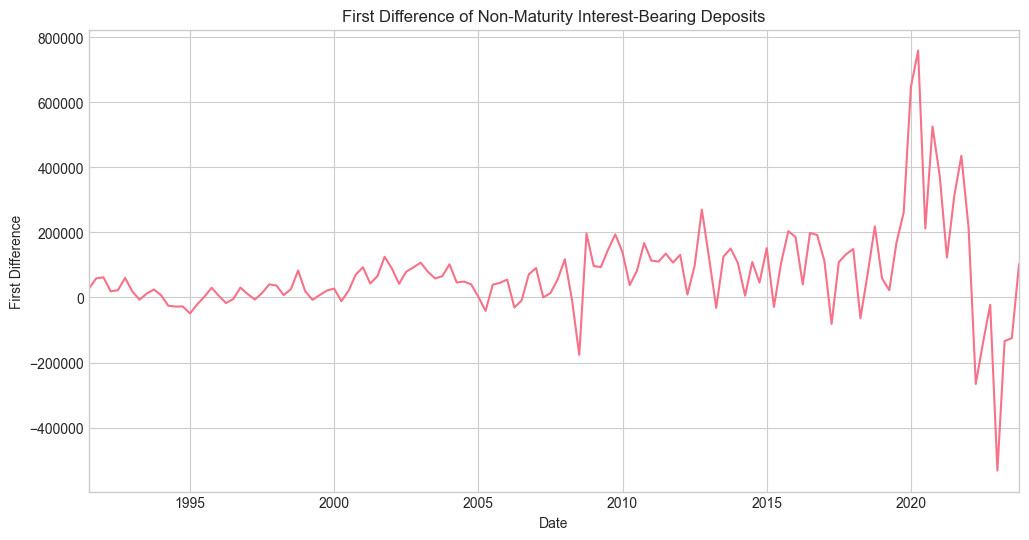

In [17]:
plt.figure(figsize=(12, 6))
y_diff.plot(title='First Difference of Non-Maturity Interest-Bearing Deposits')
plt.ylabel('First Difference')
plt.xlabel('Date')
plt.grid(True)
plt.show()

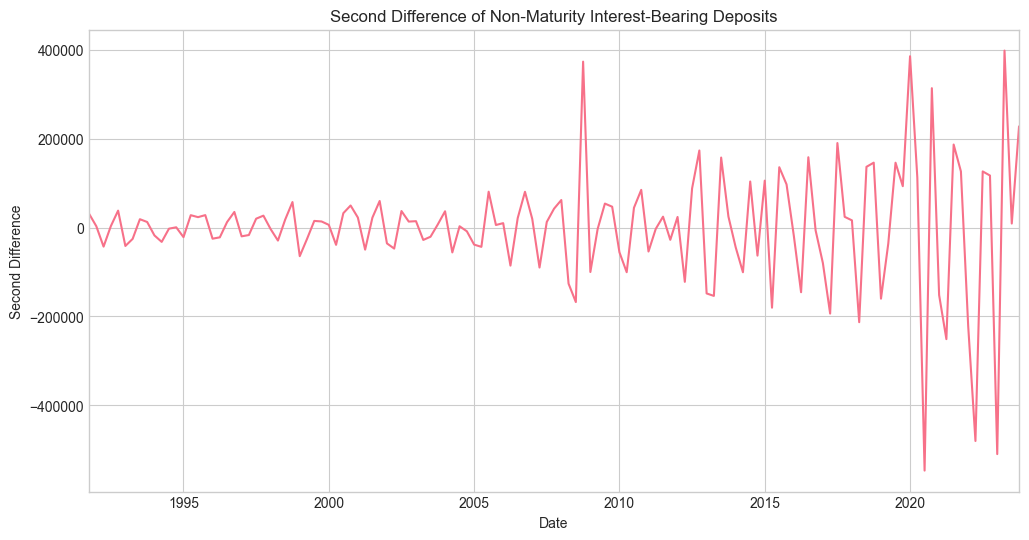

In [18]:
plt.figure(figsize=(12, 6))
y_diff2.plot(title='Second Difference of Non-Maturity Interest-Bearing Deposits')
plt.ylabel('Second Difference')
plt.xlabel('Date')
plt.grid(True)
plt.show()

In [19]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

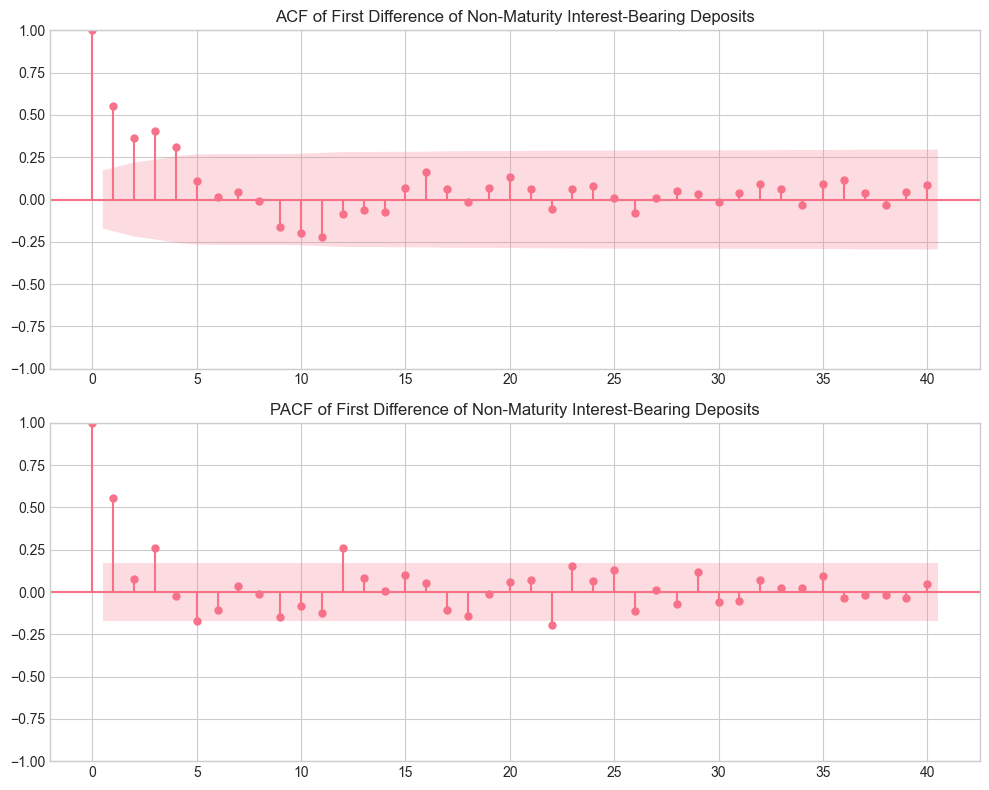

In [20]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
plot_acf(y_diff, lags=40, ax=axes[0])
axes[0].set_title('ACF of First Difference of Non-Maturity Interest-Bearing Deposits')
plot_pacf(y_diff, lags=40, ax=axes[1], method='ywm')
axes[1].set_title('PACF of First Difference of Non-Maturity Interest-Bearing Deposits')
plt.tight_layout()
plt.savefig('graphs/non-maturity-IB/non-maturity-IB_acf_pacf.png')
plt.show()

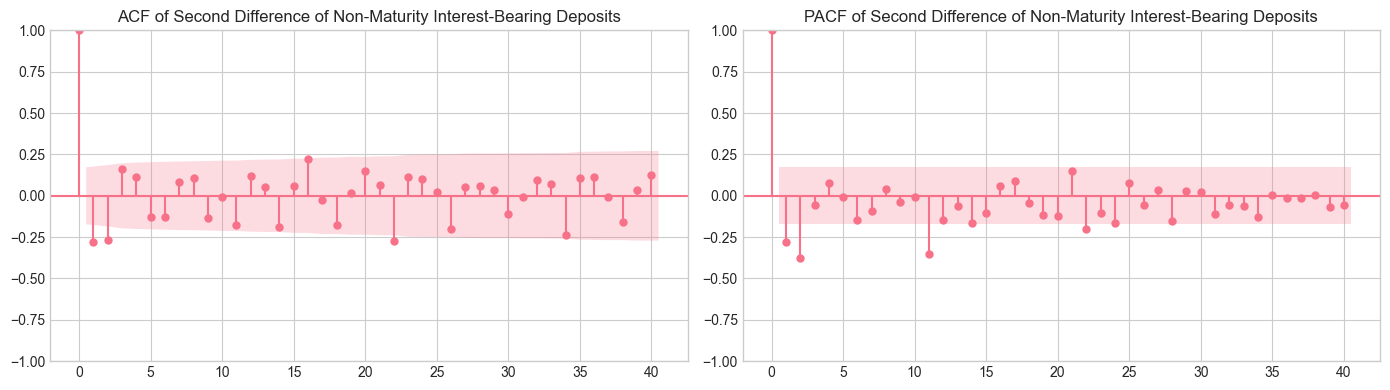

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(y_diff2, lags=40, ax=axes[0])
axes[0].set_title('ACF of Second Difference of Non-Maturity Interest-Bearing Deposits')
plot_pacf(y_diff2, lags=40, ax=axes[1], method='ywm')
axes[1].set_title('PACF of Second Difference of Non-Maturity Interest-Bearing Deposits')
plt.tight_layout()
# plt.savefig('graphs/non-maturity-IB/non-maturity-IB_acf_pacf.png')
plt.show()

In [22]:
from statsmodels.tsa.stattools import kpss

In [23]:
# KPSS test with proper interpretation
kpss_stat, p_value, lags, critical_values = kpss(y_diff.dropna(), regression='c')

print(f"KPSS Statistic: {kpss_stat:.4f}")
print(f"P-value: {p_value:.4f} (lower bound)")
print(f"Lags used: {lags}")
print(f"Critical Values: {critical_values}")

# Better interpretation accounting for the warning
if kpss_stat < critical_values['10%']:
    print(f"KPSS: Strong evidence of stationarity (stat {kpss_stat:.4f} < 10% critical {critical_values['10%']:.3f})")
    print("Note: Actual p-value > 0.10, indicating very strong stationarity")
elif p_value > 0.05:
    print("KPSS: Series is stationary")
else:
    print("KPSS: Series is non-stationary")


KPSS Statistic: 0.4519
P-value: 0.0548 (lower bound)
Lags used: 5
Critical Values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}
KPSS: Series is stationary


In [24]:
from arch.unitroot import PhillipsPerron

In [25]:
# Phillips–Perron test on first differenced data
pp_test = PhillipsPerron(y_diff.dropna(), lags=None, trend='c')
print(pp_test.summary())

# Access individual results
print(f"PP Statistic: {pp_test.stat:.4f}")
print(f"P-value: {pp_test.pvalue:.10f}")
print(f"Lags: {pp_test.lags}")
print(f"Critical Values: {pp_test.critical_values}")


     Phillips-Perron Test (Z-tau)    
Test Statistic                 -6.240
P-value                         0.000
Lags                               13
-------------------------------------

Trend: Constant
Critical Values: -3.48 (1%), -2.88 (5%), -2.58 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.
PP Statistic: -6.2398
P-value: 0.0000000473
Lags: 13
Critical Values: {'1%': -3.482087964046026, '5%': -2.8842185101614626, '10%': -2.578864381347275}


In [26]:
# Exclude the last two columns from X
X_no_dummies = X.iloc[:, :-2]
X_no_dummies.head()

,Real GDP growth,Real disposable income growth,Unemployment rate,Consumer Price Index (Level),CPI inflation rate,3-month Treasury rate,5-year Treasury yield,Prime rate,Dow Jones Total Stock Market Index (Level),House Price Index (Level),Market Volatility Index (Level)
Date,,,,,,,,,,,
1991-06-30,3.2,3.0,6.8,135.567,2.4,5.6,7.8,8.7,3545.5,75.5,20.1
1991-09-30,2.0,1.5,6.9,136.600,3.1,5.4,7.5,8.4,3744.0,75.2,21.2
1991-12-31,1.4,3.2,7.1,137.733,3.4,4.5,6.7,7.6,4041.1,75.0,21.9
1992-03-31,4.9,7.9,7.4,138.667,2.7,3.9,6.7,6.5,3961.6,75.2,19.8
1992-06-30,4.4,3.8,7.6,139.733,3.1,3.7,6.7,6.5,3930.3,75.0,20.2


In [27]:
from statsmodels.tsa.stattools import adfuller, kpss
from arch.unitroot import PhillipsPerron

In [28]:
# Differencing the Economic Varibles with "Levels"/ Absolute data

X_levels = pd.DataFrame(index=X.index)
with_levels = ['Consumer Price Index (Level)', 'Dow Jones Total Stock Market Index (Level)', 
         'House Price Index (Level)', 'Market Volatility Index (Level)']

for var in with_levels:
    X_levels[var] = X[var]


In [29]:
X_levels

,Consumer Price Index (Level),Dow Jones Total Stock Market Index (Level),House Price Index (Level),Market Volatility Index (Level)
Date,,,,
1991-06-30,135.567,3545.5,75.5,20.1
1991-09-30,136.600,3744.0,75.2,21.2
1991-12-31,137.733,4041.1,75.0,21.9
1992-03-31,138.667,3961.6,75.2,19.8
1992-06-30,139.733,3930.3,75.0,20.2
...,...,...,...,...
2022-12-31,298.441,38520.6,295.9,33.6
2023-03-31,301.203,41136.6,299.4,26.5
2023-06-30,303.467,44411.5,303.0,20.1


In [30]:
# Function to run tests and get results
def run_stationarity_tests(series):
    results = {}
    # Original series
    adf = adfuller(series.dropna(), regression='c')
    kpss_result = kpss(series.dropna(), regression='c')
    pp = PhillipsPerron(series.dropna(), trend='c', lags=None)  # Using arch.unitroot PhillipsPerron
    results['orig'] = {
        'adf_stat': adf[0], 'adf_p': adf[1], 'adf_5%': adf[4]['5%'],
        'kpss_stat': kpss_result[0], 'kpss_p': kpss_result[1], 'kpss_5%': kpss_result[3]['5%'],
        'pp_stat': pp.stat, 'pp_p': pp.pvalue, 'pp_5%': pp.critical_values['5%']
    }
    # First difference
    diff1 = series.diff().dropna()
    adf_diff1 = adfuller(diff1, regression='c')
    kpss_diff1 = kpss(diff1, regression='c')
    pp_diff1 = PhillipsPerron(diff1, trend='c', lags=None)
    results['diff1'] = {
        'adf_stat': adf_diff1[0], 'adf_p': adf_diff1[1], 'adf_5%': adf_diff1[4]['5%'],
        'kpss_stat': kpss_diff1[0], 'kpss_p': kpss_diff1[1], 'kpss_5%': kpss_diff1[3]['5%'],
        'pp_stat': pp_diff1.stat, 'pp_p': pp_diff1.pvalue, 'pp_5%': pp_diff1.critical_values['5%']
    }
    # Second difference
    diff2 = diff1.diff().dropna()
    adf_diff2 = adfuller(diff2, regression='c')
    kpss_diff2 = kpss(diff2, regression='c')
    pp_diff2 = PhillipsPerron(diff2, trend='c', lags=None)
    results['diff2'] = {
        'adf_stat': adf_diff2[0], 'adf_p': adf_diff2[1], 'adf_5%': adf_diff2[4]['5%'],
        'kpss_stat': kpss_diff2[0], 'kpss_p': kpss_diff2[1], 'kpss_5%': kpss_diff2[3]['5%'],
        'pp_stat': pp_diff2.stat, 'pp_p': pp_diff2.pvalue, 'pp_5%': pp_diff2.critical_values['5%']
    }
    return results

In [31]:
# Differencing the Economic Varibles with "Levels"/ Absolute data
# Run tests for each exogenous variable
for var in with_levels:
    results = run_stationarity_tests(X_levels[var])
    print(f"\n{var}:")
    for diff, stats in results.items():
        print(f"{diff}:")
        print(f"  ADF Statistic: {stats['adf_stat']:.4f}, p-value: {stats['adf_p']:.4f}, 5% CI: {stats['adf_5%']:.4f}")
        print(f"  KPSS Statistic: {stats['kpss_stat']:.4f}, p-value: {stats['kpss_p']:.4f}, 5% CI: {stats['kpss_5%']:.4f}")
        print(f"  PP Statistic: {stats['pp_stat']:.4f}, p-value: {stats['pp_p']:.4f}, 5% CI: {stats['pp_5%']:.4f}")


Consumer Price Index (Level):
orig:
  ADF Statistic: 2.0566, p-value: 0.9987, 5% CI: -2.8842
  KPSS Statistic: 1.9495, p-value: 0.0100, 5% CI: 0.4630
  PP Statistic: 2.0927, p-value: 0.9988, 5% CI: -2.8840
diff1:
  ADF Statistic: -6.3450, p-value: 0.0000, 5% CI: -2.8842
  KPSS Statistic: 0.4578, p-value: 0.0522, 5% CI: 0.4630
  PP Statistic: -6.8860, p-value: 0.0000, 5% CI: -2.8842
diff2:
  ADF Statistic: -8.7378, p-value: 0.0000, 5% CI: -2.8850
  KPSS Statistic: 0.1780, p-value: 0.1000, 5% CI: 0.4630
  PP Statistic: -25.1841, p-value: 0.0000, 5% CI: -2.8844

Dow Jones Total Stock Market Index (Level):
orig:
  ADF Statistic: 2.0707, p-value: 0.9988, 5% CI: -2.8857
  KPSS Statistic: 1.6023, p-value: 0.0100, 5% CI: 0.4630
  PP Statistic: 2.2795, p-value: 0.9989, 5% CI: -2.8840
diff1:
  ADF Statistic: -3.5386, p-value: 0.0070, 5% CI: -2.8857
  KPSS Statistic: 0.3035, p-value: 0.1000, 5% CI: 0.4630
  PP Statistic: -11.3006, p-value: 0.0000, 5% CI: -2.8842
diff2:
  ADF Statistic: -6.0617, 

/var/folders/p2/s867_82x1zb758ysgxvlj2yw0000gn/T/ipykernel_55064/3820424706.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(series.dropna(), regression='c')
/var/folders/p2/s867_82x1zb758ysgxvlj2yw0000gn/T/ipykernel_55064/3820424706.py:26: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_diff2 = kpss(diff2, regression='c')
/var/folders/p2/s867_82x1zb758ysgxvlj2yw0000gn/T/ipykernel_55064/3820424706.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(series.dropna(), regression='c')
/var/folders/p2/s867_82x1zb758ysgxvlj2yw0000gn/T/ipykernel_55064/3820424706.py:16: InterpolationWarni

In [32]:
X_updated = pd.DataFrame(index=X.index)

# Columns to exclude and difference
exclude_cols = [
    'Consumer Price Index (Level)', 
    'Dow Jones Total Stock Market Index (Level)', 
    'House Price Index (Level)'
]

# Drop excluded columns
X_updated = X.drop(columns=exclude_cols).copy()

# Add differenced versions of excluded columns
for col in exclude_cols:
    X_updated[f"{col}_diff"] = X[col].diff()

In [33]:
X_updated

,Real GDP growth,Real disposable income growth,Unemployment rate,CPI inflation rate,3-month Treasury rate,5-year Treasury yield,Prime rate,Market Volatility Index (Level),GFC_Dummy,COVID_Dummy,Consumer Price Index (Level)_diff,Dow Jones Total Stock Market Index (Level)_diff,House Price Index (Level)_diff
Date,,,,,,,,,,,,,
1991-06-30,3.2,3.0,6.8,2.4,5.6,7.8,8.7,20.1,0,0,NaN,NaN,NaN
1991-09-30,2.0,1.5,6.9,3.1,5.4,7.5,8.4,21.2,0,0,1.033,198.5,-0.3
1991-12-31,1.4,3.2,7.1,3.4,4.5,6.7,7.6,21.9,0,0,1.133,297.1,-0.2
1992-03-31,4.9,7.9,7.4,2.7,3.9,6.7,6.5,19.8,0,0,0.934,-79.5,0.2
1992-06-30,4.4,3.8,7.6,3.1,3.7,6.7,6.5,20.2,0,0,1.066,-31.3,-0.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-12-31,2.6,2.2,3.6,4.2,4.0,4.1,6.8,33.6,0,0,2.932,2422.6,0.1
2023-03-31,2.2,10.8,3.5,3.8,4.6,3.8,7.7,26.5,0,0,2.762,2616.0,3.5
2023-06-30,2.1,3.3,3.6,2.7,5.1,3.7,8.2,20.1,0,0,2.264,3274.9,3.6


In [34]:
from statsmodels.tsa.stattools import grangercausalitytests

In [35]:
granger_results = {}

for col in X_updated.columns:
    if 'Dummy' in col:
        continue
    data = pd.concat([y_diff, X_updated[col]], axis=1).dropna()
    data.columns = ['deposits', col]
    
    print(f"\nGranger Causality Test between Non-Maturity Interest-Bearing Deposits and {col}")
    # Call without the deprecated verbose argument
    test_result = grangercausalitytests(data, maxlag=4)
    
    p_values = {
        f'lag_{lag}': round(test_result[lag][0]['ssr_ftest'][1], 4)
        for lag in range(1, 5)
    }
    granger_results[col] = p_values

granger_df = pd.DataFrame(granger_results).T
print("\nGranger Causality Test Results (p-values):")
print(granger_df)

print("\nSignificant Granger causality (p < 0.05):")
for var, row in granger_df.iterrows():
    for lag, p in row.items():
        if p < 0.05:
            print(f"{var} at {lag}: p = {p}")



Granger Causality Test between Non-Maturity Interest-Bearing Deposits and Real GDP growth

Granger Causality
number of lags (no zero) 1
ssr based F test:         F=8.5616  , p=0.0041  , df_denom=126, df_num=1
ssr based chi2 test:   chi2=8.7655  , p=0.0031  , df=1
likelihood ratio test: chi2=8.4805  , p=0.0036  , df=1
parameter F test:         F=8.5616  , p=0.0041  , df_denom=126, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=4.4568  , p=0.0135  , df_denom=123, df_num=2
ssr based chi2 test:   chi2=9.2758  , p=0.0097  , df=2
likelihood ratio test: chi2=8.9552  , p=0.0114  , df=2
parameter F test:         F=4.4568  , p=0.0135  , df_denom=123, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=2.9759  , p=0.0344  , df_denom=120, df_num=3
ssr based chi2 test:   chi2=9.4485  , p=0.0239  , df=3
likelihood ratio test: chi2=9.1135  , p=0.0278  , df=3
parameter F test:         F=2.9759  , p=0.0344  , df_denom=120, df_num=3

Gr

Key drivers of deposits (with lags): Real GDP growth, Real disposable income growth, Unemployment, 5-year Treasury yield, House prices, CPI inflation, 3-month Treasury rate, CPI level_diff

No evidence of causality: Prime rate, VIX, Stock market returns

Deposits are not random — they reflect fundamental macro conditions. Households increase NMDs when income grows, yields fall, or uncertainty about jobs/economy rises. They decline when inflation or housing costs eat into liquidity, or when bond yields offer better alternatives

In [36]:
# Original dataframe X and deposits series
# X: contains columns ['Real GDP growth', 'Real disposable income growth', 
#                       'Unemployment rate', 'Consumer Price Index (Level)', 'CPI inflation rate', 
#                        '3-month Treasury rate', '5-year Treasury yield', 'Prime rate', 
#                          'Dow Jones Total Stock Market Index (Level)', 'House Price Index (Level)', 
#                           'Market Volatility Index (Level)','GFC_Dummy', 'COVID_Dummy']
# y: non-maturity interest-bearing deposits series

#Create lagged variables
exog_lags = pd.DataFrame({
    'Real GDP growth_lag1': X_updated['Real GDP growth'].shift(1),
    'Real disposable income growth_lag4': X_updated['Real disposable income growth'].shift(4),
    'Unemployment rate_lag3': X_updated['Unemployment rate'].shift(3),
    'CPI_Level_diff_lag3': X_updated['Consumer Price Index (Level)_diff'].shift(3),
    'CPI inflation rate_lag3': X_updated['CPI inflation rate'].shift(3),
    '3-month Treasury rate_lag2': X_updated['3-month Treasury rate'].shift(2),
    '5-year Treasury yield_lag2': X_updated['5-year Treasury yield'].shift(2),
    'Prime rate_lag1': X_updated['Prime rate'].shift(1), 
    'Dow Jones Total Stock Market Index (Level)_diff_lag2': X_updated['Dow Jones Total Stock Market Index (Level)_diff'].shift(2),
    'House Price Index (Level)_diff_lag3': X_updated['House Price Index (Level)_diff'].shift(3),
    'Market Volatility Index (Level)_lag1': X_updated['Market Volatility Index (Level)'].shift(1),
    'GFC_Dummy': X_updated['GFC_Dummy'],
    'COVID_Dummy': X_updated['COVID_Dummy']
})

# Drop rows with NaNs from lagging
exog_final = exog_lags.dropna()

In [37]:
exog_final.head()

,Real GDP growth_lag1,Real disposable income growth_lag4,Unemployment rate_lag3,CPI_Level_diff_lag3,CPI inflation rate_lag3,3-month Treasury rate_lag2,5-year Treasury yield_lag2,Prime rate_lag1,Dow Jones Total Stock Market Index (Level)_diff_lag2,House Price Index (Level)_diff_lag3,Market Volatility Index (Level)_lag1,GFC_Dummy,COVID_Dummy
Date,,,,,,,,,,,,,
1992-06-30,4.9,3.0,6.9,1.033,3.1,4.5,6.7,6.5,297.1,-0.3,19.8,0,0
1992-09-30,4.4,1.5,7.1,1.133,3.4,3.9,6.7,6.5,-79.5,-0.2,20.2,0,0
1992-12-31,4.0,3.2,7.4,0.934,2.7,3.7,6.7,6.0,-31.3,0.2,16.2,0,0
1993-03-31,4.2,7.9,7.6,1.066,3.1,3.1,5.7,6.0,94.1,-0.2,21.0,0,0
1993-06-30,0.7,3.8,7.6,1.067,3.1,3.1,6.0,6.0,265.3,-0.1,16.2,0,0


In [38]:
exog_final.tail(15)

,Real GDP growth_lag1,Real disposable income growth_lag4,Unemployment rate_lag3,CPI_Level_diff_lag3,CPI inflation rate_lag3,3-month Treasury rate_lag2,5-year Treasury yield_lag2,Prime rate_lag1,Dow Jones Total Stock Market Index (Level)_diff_lag2,House Price Index (Level)_diff_lag3,Market Volatility Index (Level)_lag1,GFC_Dummy,COVID_Dummy
Date,,,,,,,,,,,,,
2020-06-30,-5.3,-0.3,3.6,0.842,1.4,1.6,1.6,4.4,2593.6,2.5,82.7,0,1
2020-09-30,-28.0,2.8,3.6,1.799,2.8,1.1,1.2,3.3,-7050.6,3.1,57.1,0,1
2020-12-31,34.8,2.3,3.8,0.879,1.4,0.1,0.4,3.3,5592.0,3.1,33.6,0,1
2021-03-31,4.2,2.4,13.0,-2.441,-3.8,0.1,0.3,3.3,2729.0,1.6,40.3,0,1
2021-06-30,5.2,45.7,8.8,2.916,4.6,0.1,0.4,3.3,4913.8,7.3,37.2,0,1
2021-09-30,6.2,-13.3,6.7,1.808,2.8,0.1,0.6,3.3,2383.1,8.5,27.6,0,1
2021-12-31,3.3,-7.7,6.2,2.620,4.2,0.0,0.8,3.3,3301.6,7.5,25.7,0,1
2022-03-31,7.0,56.0,5.9,4.953,7.5,0.0,0.8,3.3,-198.5,11.7,31.1,0,0
2022-06-30,-2.0,-27.6,5.1,4.267,6.6,0.1,1.2,3.3,3928.5,11.1,36.5,0,0


In [40]:
# Ensure y and exog_final share the same DateTimeIndex

# Join on index to drop mismatches
data = pd.concat([y, exog_final], axis=1).dropna()
y_aligned = data[y.name]
exog_aligned = data[exog_final.columns]

In [41]:
y_aligned.head()

Date
1992-06-30    1265699.776
1992-09-30    1287788.772
1992-12-31    1347926.593
1993-03-31    1366617.108
1993-06-30    1359775.602
Freq: QE-DEC, Name: Non_Maturity_IB, dtype: float64

In [58]:
import math

In [59]:
import dcor
from scipy.stats import pearsonr

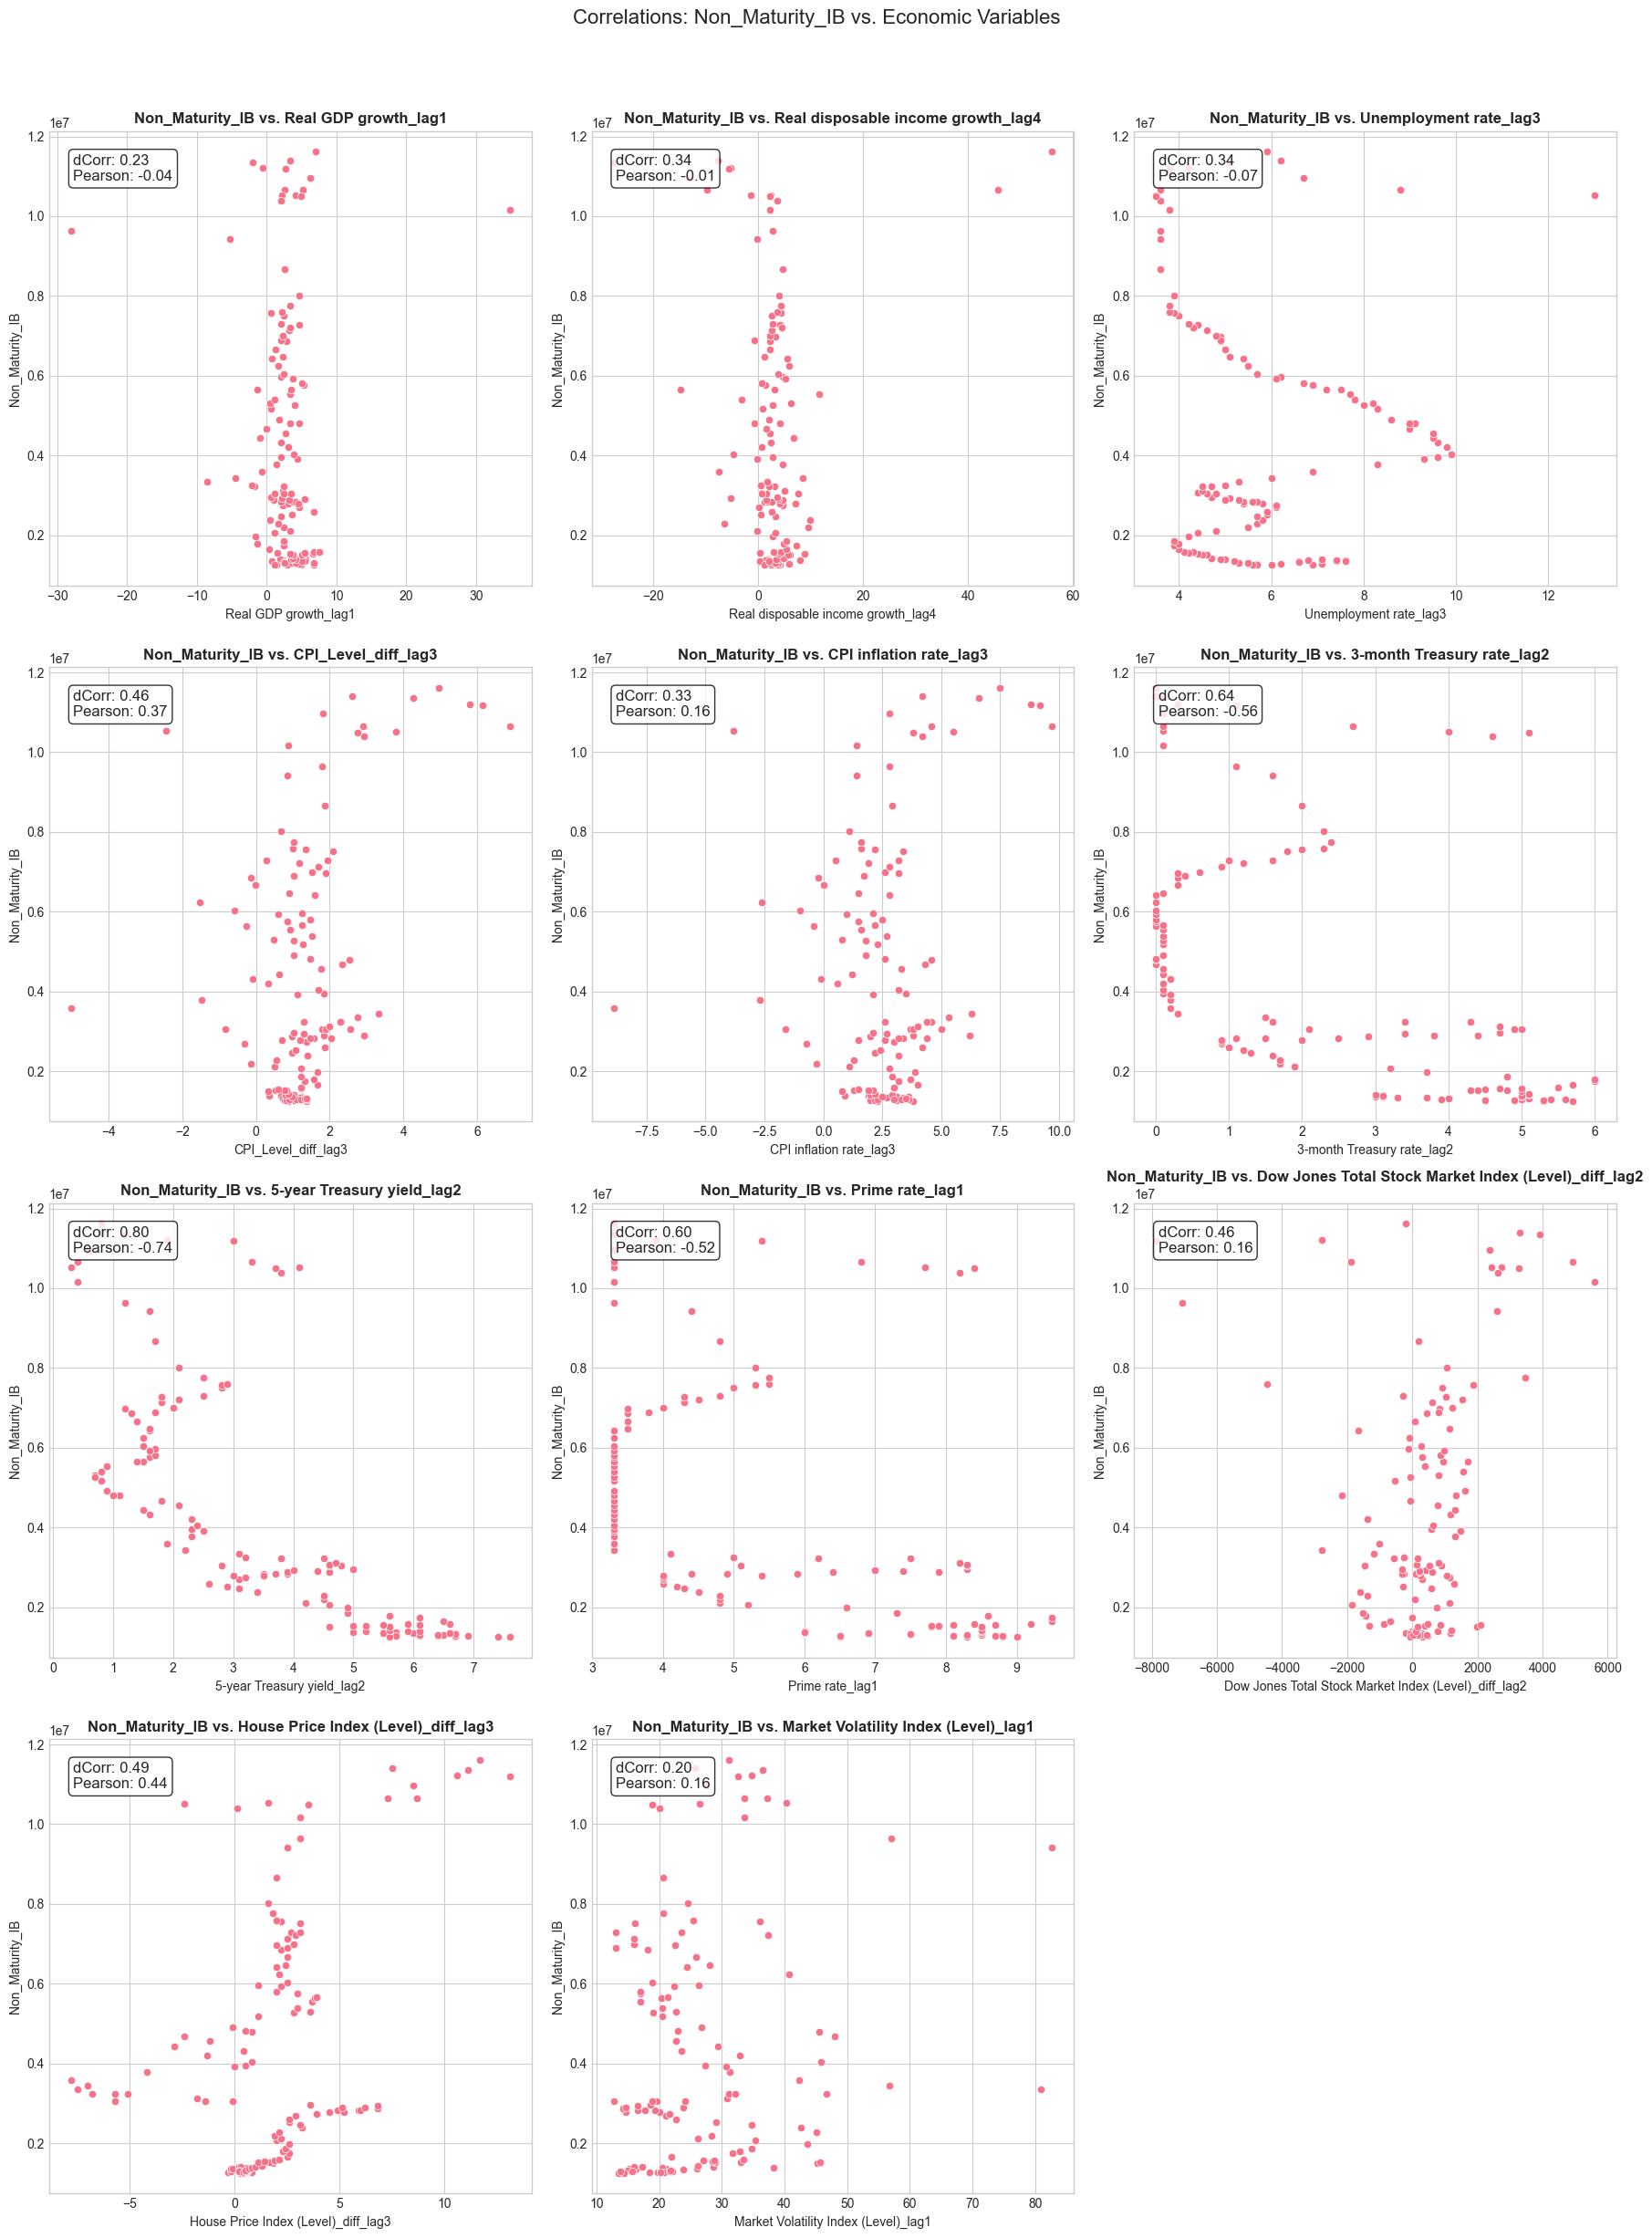

Economic variables ranked by Distance Correlation:
                                   Economic Variable dCorr
                          5-year Treasury yield_lag2  0.80
                          3-month Treasury rate_lag2  0.64
                                     Prime rate_lag1  0.60
                 House Price Index (Level)_diff_lag3  0.49
Dow Jones Total Stock Market Index (Level)_diff_lag2  0.46
                                 CPI_Level_diff_lag3  0.46
                  Real disposable income growth_lag4  0.34
                              Unemployment rate_lag3  0.34
                             CPI inflation rate_lag3  0.33
                                Real GDP growth_lag1  0.23
                Market Volatility Index (Level)_lag1  0.20

Economic variables ranked by Pearson Correlation:
                                   Economic Variable Pearson
                 House Price Index (Level)_diff_lag3    0.44
                                 CPI_Level_diff_lag3    0.37
       

In [67]:
# Correlation Graphs 

deposit_col = y_aligned.name   # Only one deposit column (Series)
econ_cols = exog_aligned.columns[:-2]  # excluding last 2 dummy cols

# Store results
results = []

# Grid size: n rows, 3 columns
n_rows = math.ceil(len(econ_cols) / 3)
fig, axes = plt.subplots(n_rows, 3, figsize=(18, 6 * n_rows))
axes = axes.flatten()  # Flatten to 1D array for easy iteration

for i, econ in enumerate(econ_cols):
    # Compute correlations
    dcorr_value = dcor.distance_correlation(y_aligned, exog_aligned[econ])
    pearson_corr, _ = pearsonr(y_aligned, exog_aligned[econ])
    
    # Save to results
    results.append({
        "Economic Variable": econ,
        "dCorr": dcorr_value,
        "Pearson": pearson_corr
    })
    
    # Scatter plot
    sns.scatterplot(x=exog_aligned[econ], y=y_aligned, ax=axes[i])
    axes[i].text(
        0.05, 0.95,
        f'dCorr: {dcorr_value:.2f}\nPearson: {pearson_corr:.2f}',
        transform=axes[i].transAxes,
        fontsize=12,
        verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
    )
    axes[i].set_title(f'{deposit_col} vs. {econ}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(econ, fontsize=10)
    axes[i].set_ylabel(deposit_col, fontsize=10)
    axes[i].tick_params(labelsize=10)

# Remove unused subplots (if any)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(f'Correlations: {deposit_col} vs. Economic Variables', y=1.02, fontsize=16)
plt.tight_layout()
plt.savefig(f'graphs/non-maturity-IB/non-maturity-IB_all_corr_plots.png', dpi=300, bbox_inches='tight')
plt.show()

# ---- Create sorted tables ----
results_df = pd.DataFrame(results)

# Sort by distance correlation
dcorr_sorted = results_df.sort_values("dCorr", ascending=False).copy()
dcorr_sorted["dCorr"] = dcorr_sorted["dCorr"].map(lambda x: f"{x:.2f}")
print("Economic variables ranked by Distance Correlation:")
print(dcorr_sorted[["Economic Variable", "dCorr"]].to_string(index=False))

# Sort by Pearson correlation
pearson_sorted = results_df.sort_values("Pearson", ascending=False).copy()
pearson_sorted["Pearson"] = pearson_sorted["Pearson"].map(lambda x: f"{x:.2f}")
print("\nEconomic variables ranked by Pearson Correlation:")
print(pearson_sorted[["Economic Variable", "Pearson"]].to_string(index=False))


In [42]:
import pmdarima as pm

In [43]:
# y_aligned: pandas Series of the target variable with DateTimeIndex
# exog_aligned: pandas DataFrame of exogenous regressors with same index

auto_model = pm.auto_arima(
    y=y_aligned,
    exogenous=exog_aligned,
    start_p=0, max_p=3,
    start_q=0, max_q=3,
    d=None,
    seasonal=True,
    m=4,              # quarterly
    start_P=0, max_P=2,
    start_Q=0, max_Q=2,
    D=None,
    information_criterion='aic',
    stepwise=True,
    trace=True,
    error_action='ignore'
    # omit n_jobs to avoid the parallel warning
)

print(auto_model.summary())

Performing stepwise search to minimize aic
 ARIMA(0,2,0)(0,0,0)[4]             : AIC=3309.889, Time=0.01 sec
 ARIMA(1,2,0)(1,0,0)[4]             : AIC=3306.070, Time=0.02 sec
 ARIMA(0,2,1)(0,0,1)[4]             : AIC=3298.668, Time=0.02 sec
 ARIMA(0,2,1)(0,0,0)[4]             : AIC=3297.357, Time=0.01 sec
 ARIMA(0,2,1)(1,0,0)[4]             : AIC=3298.615, Time=0.02 sec
 ARIMA(0,2,1)(1,0,1)[4]             : AIC=3297.455, Time=0.03 sec
 ARIMA(1,2,1)(0,0,0)[4]             : AIC=3287.660, Time=0.02 sec
 ARIMA(1,2,1)(1,0,0)[4]             : AIC=3288.674, Time=0.04 sec
 ARIMA(1,2,1)(0,0,1)[4]             : AIC=3288.715, Time=0.04 sec
 ARIMA(1,2,1)(1,0,1)[4]             : AIC=inf, Time=0.06 sec
 ARIMA(1,2,0)(0,0,0)[4]             : AIC=3304.902, Time=0.01 sec
 ARIMA(2,2,1)(0,0,0)[4]             : AIC=3293.979, Time=0.02 sec
 ARIMA(1,2,2)(0,0,0)[4]             : AIC=3294.115, Time=0.02 sec
 ARIMA(0,2,2)(0,0,0)[4]             : AIC=3292.178, Time=0.01 sec
 ARIMA(2,2,0)(0,0,0)[4]             : 

#### Time series cross-validation

Anchor rolling windows around the key regime shifts rather than fixed jumps.


1992-06-30 → 1999-12-31 trains up to just before Q1 2000, tests Q1 2000–Q4 2001 (dot-com aftermath).

1994-06-30 → 2001-12-31 shifts forward 2 years, so training now covers the dot-com peak and early GFC build-up; tests Q1 2002–Q4 2003.

1999-06-30 → 2006-12-31 captures the full build-up to the GFC; tests Q1 2007–Q4 2008 (GFC onset).

2004-06-30 → 2011-12-31 trains through the GFC trough and early recovery; tests Q1 2012–Q4 2013.

2009-06-30 → 2016-12-31 starts mid-crisis recovery through the pre-COVID expansion; tests Q1 2017–Q4 2018.

2014-06-30 → 2021-06-30 trains through the COVID shock and stimulus period; tests Q3 2021–Q4 2023.

In [39]:
import statsmodels.api as sm

In [44]:
from sklearn.metrics import root_mean_squared_error, r2_score, mean_absolute_percentage_error

In [45]:
import matplotlib.dates as mdates

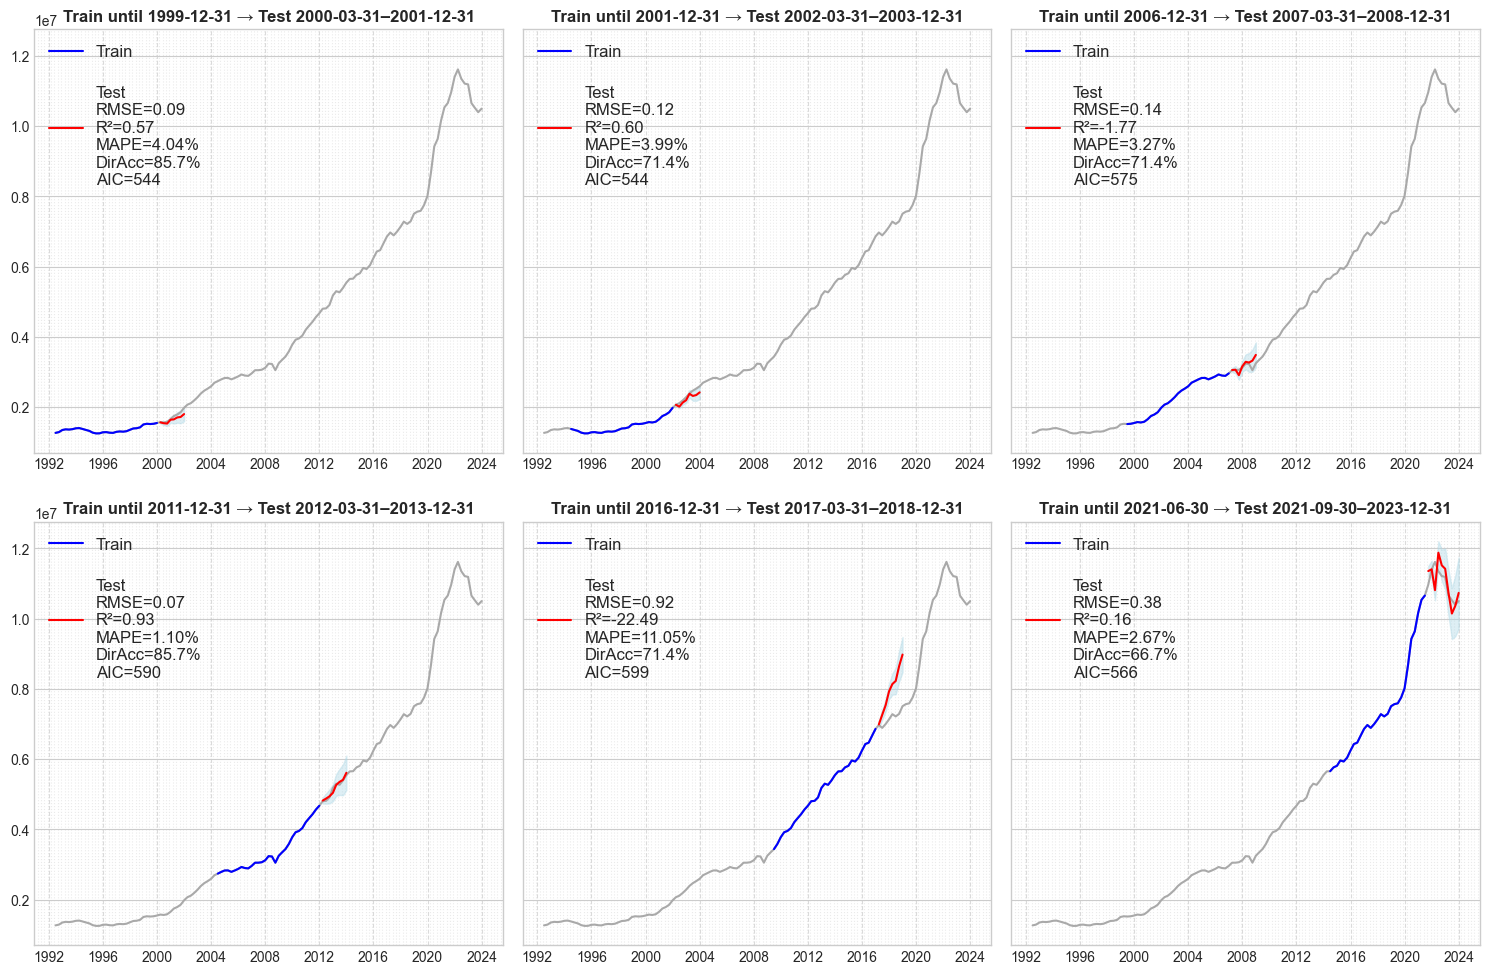

In [46]:
# Cross-validation folds
folds = [
    # Pre-dot-com test
    ('1992-06-30', '1999-12-31', '2000-03-31', '2001-12-31'),
    # Dot-com + early GFC test
    ('1994-06-30', '2001-12-31', '2002-03-31', '2003-12-31'),
    # Run-up through the GFC test
    ('1999-06-30', '2006-12-31', '2007-03-31', '2008-12-31'),
    # GFC + early recovery test
    ('2004-06-30', '2011-12-31', '2012-03-31', '2013-12-31'),
    # Mid-cycle test before COVID
    ('2009-06-30', '2016-12-31', '2017-03-31', '2018-12-31'),
    # COVID-era test
    ('2014-06-30', '2021-06-30', '2021-09-30', '2023-12-31'),
]


def directional_accuracy(y_true, y_pred):
    return np.mean(np.sign(y_true.diff().dropna()) == np.sign(y_pred.diff().dropna())) * 100

fig, axes = plt.subplots(2, 3, figsize=(15, 10), sharey=True)
axes = axes.flatten()

for ax, (start, train_end, test_start, test_end) in zip(axes, folds):
    # Split
    y_train = y_aligned[start:train_end]
    exog_train = exog_aligned[start:train_end]
    y_test = y_aligned[test_start:test_end]
    exog_test = exog_aligned[test_start:test_end]
    
    # Fit
    model = sm.tsa.SARIMAX(
        endog=y_train,
        exog=exog_train,
        order=(3,1,1),
        seasonal_order=(0,1,0,4),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    res = model.fit(
        disp=False,
        method='lbfgs',      # use L-BFGS optimizer
        maxiter=100000,         # increase max iterations
        # full_output=True     # ensure optimization output is shown
    )

    # Predict
    pred = res.get_prediction(start=test_start, end=test_end, exog=exog_test)
    ci = pred.conf_int(alpha=0.05)
 
    y_pred = pred.predicted_mean
    
    # Metrics
    rmse = root_mean_squared_error(y_test, y_pred)/10**6  # in millions
    r2 = r2_score(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred)
    dir_acc = directional_accuracy(y_test, y_pred)
    aic = res.aic
    
    # Plot
    ax.plot(y_aligned, color='darkgray')
    ax.plot(y_train, color='blue', label='Train')
    ax.plot(
        y_test.index,
        y_pred,
        color='red',
        label=(
            f"\nTest\n"
            f"RMSE={rmse:.2f}\n"
            f"R²={r2:.2f}\n"
            f"MAPE={mape:.2%}\n"
            f"DirAcc={dir_acc:.1f}%\n"
            f"AIC={aic:.0f}"
        )
    )

    ax.legend(loc='upper left', fontsize=12, framealpha=0.9)

    ax.set_title(f'Train until {train_end} → Test {test_start}–{test_end}', fontweight='bold', fontsize=12)

    ax.fill_between(
        y_pred.index,
        ci.iloc[:, 0],
        ci.iloc[:, 1],
        color='lightblue', 
        alpha=0.4,
        label='95% CI'
    )

    # Set x-axis grid for each date (quarter)
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[3, 6, 9, 12]))
    ax.grid(True, which='major', axis='x', linestyle='--', alpha=0.7)
    ax.grid(True, which='minor', axis='x', linestyle=':', alpha=0.4)
    

plt.tight_layout()
plt.savefig('graphs/non-maturity-IB/non-maturity-IB_cross_validation.png')
plt.show()

In [47]:
y_test

Date
2021-09-30    1.096635e+07
2021-12-31    1.140195e+07
2022-03-31    1.161638e+07
2022-06-30    1.135061e+07
2022-09-30    1.121112e+07
2022-12-31    1.118861e+07
2023-03-31    1.065641e+07
2023-06-30    1.052234e+07
2023-09-30    1.039728e+07
2023-12-31    1.049983e+07
Freq: QE-DEC, Name: Non_Maturity_IB, dtype: float64

In [48]:
y_pred

2021-09-30    1.135491e+07
2021-12-31    1.140412e+07
2022-03-31    1.081166e+07
2022-06-30    1.187814e+07
2022-09-30    1.151759e+07
2022-12-31    1.142001e+07
2023-03-31    1.072942e+07
2023-06-30    1.014518e+07
2023-09-30    1.036494e+07
2023-12-31    1.073303e+07
Freq: QE-DEC, Name: predicted_mean, dtype: float64

In [49]:
# Test residuals
resid_test = (y_test - y_pred).dropna()
std_resid  = (resid_test - resid_test.mean()) / resid_test.std(ddof=0)

In [50]:
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
from scipy import stats

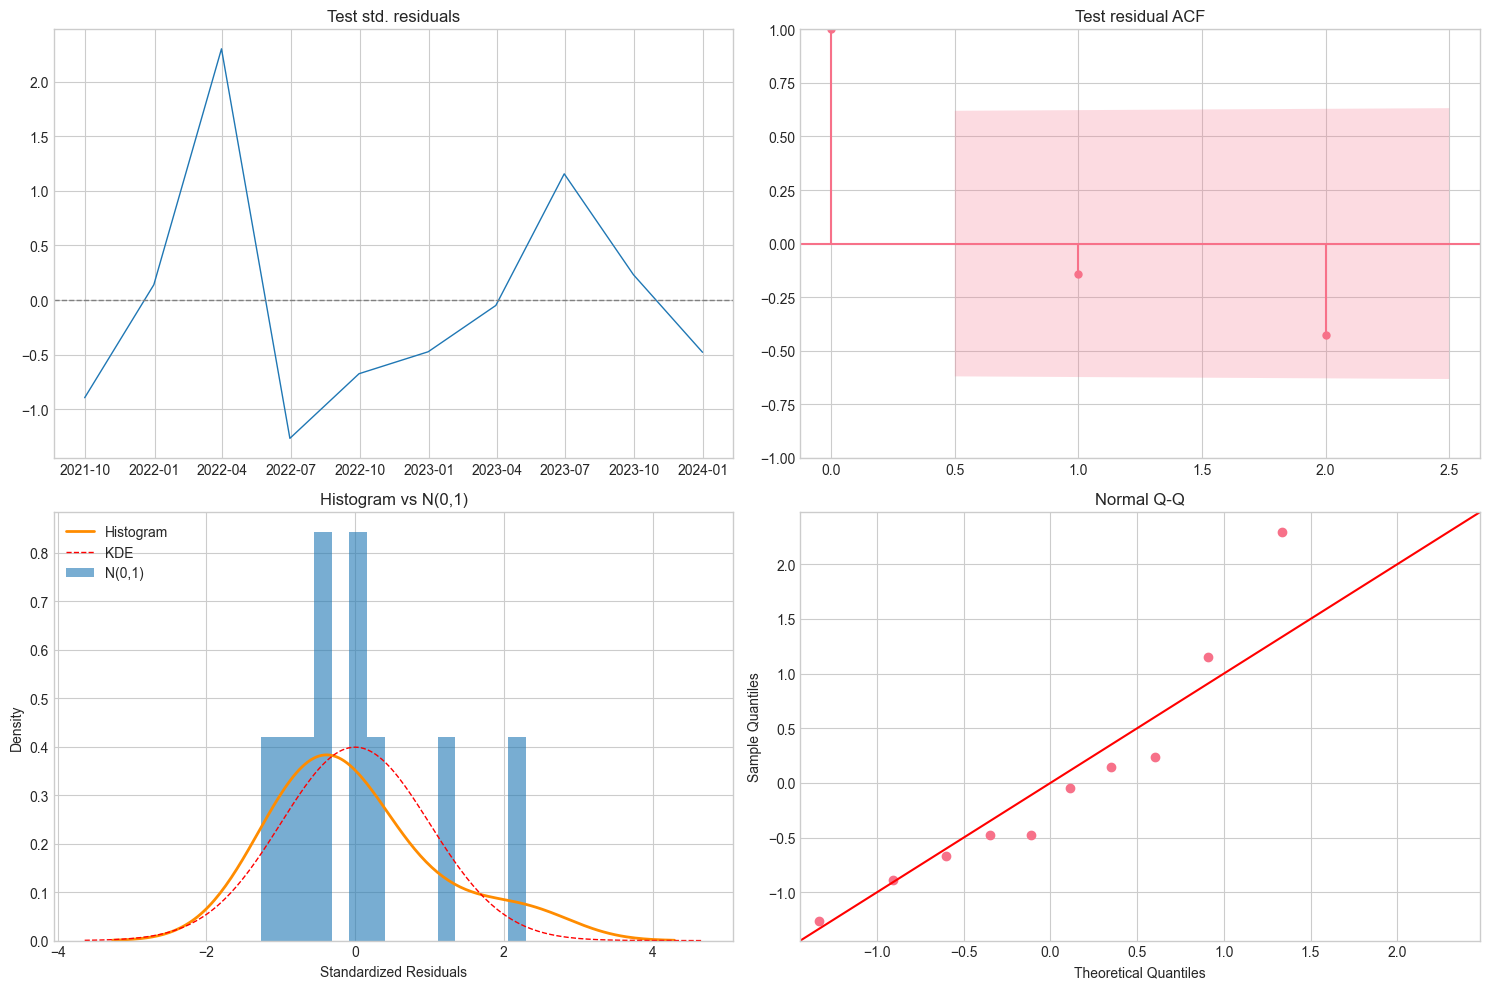

In [51]:
# Residual diagnostics

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Residuals over time
axes[0, 0].plot(std_resid, lw=1, color='tab:blue')
axes[0, 0].axhline(0, color='gray', ls='--', lw=1)
axes[0, 0].set_title('Test std. residuals')

# ACF of standardized residuals
plot_acf(std_resid, lags=min(12, max(1, len(std_resid)//5)), ax=axes[0, 1])
axes[0, 1].set_title('Test residual ACF')

# Histogram of standardized residuals
axes[1, 0].hist(std_resid, bins=15, density=True, alpha=0.6, color='tab:blue')
sns.kdeplot(std_resid, ax=axes[1, 0], color='darkorange', lw=2) # plot kernel density estimate
xs = np.linspace(*axes[1, 0].get_xlim(), 200) # plot normal distribution for comparison
axes[1, 0].plot(xs, stats.norm.pdf(xs, 0, 1), 'r--', lw=1)
axes[1, 0].set_title('Histogram vs N(0,1)')
axes[1, 0].set_xlabel('Standardized Residuals')
axes[1, 0].set_ylabel('Density')
axes[1, 0].legend(['Histogram', 'KDE', 'N(0,1)'], loc='upper left')

# Q-Q plot of standardized residuals
sm.ProbPlot(std_resid).qqplot(line='45', ax=axes[1, 1])
axes[1, 1].set_title('Normal Q-Q')

plt.tight_layout()
plt.savefig('graphs/non-maturity-IB/non-maturity-IB_residual_diagnostics.png')
plt.show()


In [52]:
# Statistics on test residuals

# Check residual sample size and adjust lags accordingly
n_resid = len(std_resid)
max_safe_lag = max(1, n_resid // 2 - 1)  # Ensure at least 1 lag but don't exceed sample limits
test_lags = [lag for lag in [4, 8, 12] if lag <= max_safe_lag]

if test_lags:  # Only run if we have valid lags
    lb = acorr_ljungbox(std_resid, lags=test_lags, return_df=True)
    print('Ljung–Box p-values:', {int(k): float(v) for k, v in lb['lb_pvalue'].to_dict().items()})
else:
    print(f'Sample too small (n={n_resid}) for meaningful Ljung-Box test')

jb_stat, jb_p, skew, kurt = jarque_bera(std_resid)
print(f'Jarque–Bera: stat={jb_stat:.3f}, p={jb_p:.3f}, skew={skew:.3f}, kurt={kurt:.3f}')



Ljung–Box p-values: {4: 0.5089100068014785}
Jarque–Bera: stat=1.869, p=0.393, skew=1.046, kurt=3.324


In [53]:
#Load scenarios data
scenarios = pd.read_csv('extracted_data/scenarios.csv', index_col=['Scenario Name', 'Date'], parse_dates=['Date'], date_format='%Y-%m-%d')

In [54]:
scenarios.head()

Real GDP  Real GDP growth   Nominal GDP  \
Scenario Name        Date                                                      
Supervisory Baseline 2024-03-31  22735.953138              1.0  28180.653984   
                     2024-06-30  22775.741055              0.7  28384.963725   
                     2024-09-30  22826.986473              0.9  28604.947194   
                     2024-12-31  22912.587672              1.5  28862.391719   
                     2025-03-31  23015.694317              1.8  29158.231234   

                                 Nominal GDP growth  Real disposable income  \
Scenario Name        Date                                                     
Supervisory Baseline 2024-03-31                 3.2            16961.584792   
                     2024-06-30                 2.9            17037.911923   
                     2024-09-30                 3.1            17114.582527   
                     2024-12-31                 3.6            17200.155440   
                     2025-03-31                 4.1            17303.356372   

                                 Real disposable income growth  \
Scenario Name        Date                                        
Supervisory Baseline 2024-03-31                            2.5   
                     2024-06-30                            1.8   
                     2024-09-30                            1.8   
                     2024-12-31                            2.0   
                     2025-03-31                            2.4   

                                 Nominal disposable income  \
Scenario Name        Date                                    
Supervisory Baseline 2024-03-31               20690.266217   
                     2024-06-30               20897.168879   
                     2024-09-30               21106.140568   
                     2024-12-31               21322.478508   
                     2025-03-31               21562.356392   

                                 Nominal disposable income growth  \
Scenario Name        Date                                           
Supervisory Baseline 2024-03-31                               4.6   
                     2024-06-30                               4.0   
                     2024-09-30                               4.0   
                     2024-12-31                               4.1   
                     2025-03-31                               4.5   

                                 Unemployment rate  \
Scenario Name        Date                            
Supervisory Baseline 2024-03-31                3.9   
                     2024-06-30                4.1   
                     2024-09-30                4.2   
                     2024-12-31                4.3   
                     2025-03-31                4.3   

                                 Consumer Price Index (Level)  ...  \
Scenario Name        Date                                      ...   
Supervisory Baseline 2024-03-31                    309.931186  ...   
                     2024-06-30                    311.698122  ...   
                     2024-09-30                    313.551711  ...   
                     2024-12-31                    315.339289  ...   
                     2025-03-31                    317.059527  ...   

                                 3-month Treasury rate  5-year Treasury yield  \
Scenario Name        Date                                                       
Supervisory Baseline 2024-03-31                    5.3                    4.2   
                     2024-06-30                    5.0                    4.0   
                     2024-09-30                    4.6                    3.9   
                     2024-12-31                    4.2                    3.8   
                     2025-03-31                    3.9                    3.6   

                                 10-year Treasury yield  BBB corporate yield  \
Scenario Name        D

In [55]:
# Use the complete historical base data X for proper lag calculation
# X contains the raw economic variables without lags
# exog_aligned contains the differenced and lagged variables used in the model

# Forecast horizon
forecast_dates = pd.date_range(start='2024-03-31', periods=13, freq='QE')
scenario_names = scenarios.index.get_level_values('Scenario Name').unique()
forecasts = {}

for scenario_name in scenario_names:
    scenario_data = scenarios.loc[scenario_name].copy()
    
    # Create complete time series combining historical X and scenario data
    # This ensures we have enough history to compute all required lags
    full_series = {}
    
    # Real GDP growth: need lag 1 (Granger showed lags 1-4, using max for consistency)
    full_series['Real GDP growth'] = pd.concat([
        X['Real GDP growth'],  # complete historical data
        scenario_data['Real GDP growth']  # scenario projections
    ]).drop_duplicates()
    
    # Real disposable income growth: need lag 4
    full_series['Real disposable income growth'] = pd.concat([
        X['Real disposable income growth'],
        scenario_data['Real disposable income growth']
    ]).drop_duplicates()
    
    # Unemployment rate: need lag 3
    full_series['Unemployment rate'] = pd.concat([
        X['Unemployment rate'],
        scenario_data['Unemployment rate']
    ]).drop_duplicates()
    
    # CPI inflation rate: need lag 3
    full_series['CPI inflation rate'] = pd.concat([
        X['CPI inflation rate'],
        scenario_data['CPI inflation rate']
    ]).drop_duplicates()
    
    # 3-month Treasury rate: need lag 2
    full_series['3-month Treasury rate'] = pd.concat([
        X['3-month Treasury rate'],
        scenario_data['3-month Treasury rate']
    ]).drop_duplicates()
    
    # 5-year Treasury yield: need lag 2 (Granger showed lags 1-4, using max for consistency)
    full_series['5-year Treasury yield'] = pd.concat([
        X['5-year Treasury yield'],
        scenario_data['5-year Treasury yield']
    ]).drop_duplicates()
    
    # Prime rate: need lag 1 (though Granger was weak, included for model alignment)
    full_series['Prime rate'] = pd.concat([
        X['Prime rate'],
        scenario_data['Prime rate']
    ]).drop_duplicates()
    
    # Market Volatility Index (Level): need lag 1
    full_series['Market Volatility Index (Level)'] = pd.concat([
        X['Market Volatility Index (Level)'],
        scenario_data['Market Volatility Index (Level)']
    ]).drop_duplicates()
    
    # Consumer Price Index (Level): need diff and lag 3 for forecast
    full_series['Consumer Price Index (Level)'] = pd.concat([
        X['Consumer Price Index (Level)'],
        scenario_data['Consumer Price Index (Level)']
    ]).drop_duplicates()
    
    # Dow Jones Total Stock Market Index (Level): need diff and lag 2
    full_series['Dow Jones Total Stock Market Index (Level)'] = pd.concat([
        X['Dow Jones Total Stock Market Index (Level)'],
        scenario_data['Dow Jones Total Stock Market Index (Level)']
    ]).drop_duplicates()
    
    # House Price Index (Level): need diff and lag 3
    full_series['House Price Index (Level)'] = pd.concat([
        X['House Price Index (Level)'],
        scenario_data['House Price Index (Level)']
    ]).drop_duplicates()
    
    # Now create the lagged exog matrix for forecast dates only
    scenario_X = pd.DataFrame(index=forecast_dates)
    
    # Apply lags to the full series and extract forecast period
    scenario_X['Real GDP growth_lag1'] = full_series['Real GDP growth'].shift(1).reindex(forecast_dates)
    scenario_X['Real disposable income growth_lag4'] = full_series['Real disposable income growth'].shift(4).reindex(forecast_dates)
    scenario_X['Unemployment rate_lag3'] = full_series['Unemployment rate'].shift(3).reindex(forecast_dates)
    scenario_X['CPI inflation rate_lag3'] = full_series['CPI inflation rate'].shift(3).reindex(forecast_dates)
    scenario_X['3-month Treasury rate_lag2'] = full_series['3-month Treasury rate'].shift(2).reindex(forecast_dates)
    scenario_X['5-year Treasury yield_lag2'] = full_series['5-year Treasury yield'].shift(2).reindex(forecast_dates)
    scenario_X['Prime rate_lag1'] = full_series['Prime rate'].shift(1).reindex(forecast_dates)
    scenario_X['Market Volatility Index (Level)_lag1'] = full_series['Market Volatility Index (Level)'].shift(1).reindex(forecast_dates)
    
    # CPI Level diff - compute from scenario CPI level data and lag
    scenario_X['CPI_Level_diff_lag3'] = full_series['Consumer Price Index (Level)'].diff().shift(3).reindex(forecast_dates)
    
    # Dow Jones diff - compute from scenario data and lag
    scenario_X['Dow Jones Total Stock Market Index (Level)_diff_lag2'] = full_series['Dow Jones Total Stock Market Index (Level)'].diff().shift(2).reindex(forecast_dates)
    
    # House Price Index diff - compute from scenario data and lag
    scenario_X['House Price Index (Level)_diff_lag3'] = full_series['House Price Index (Level)'].diff().shift(3).reindex(forecast_dates)
    
    # Dummies (set to 0 for future periods)
    scenario_X['GFC_Dummy'] = 0
    scenario_X['COVID_Dummy'] = 0
    
    # Reorder columns to match model specification
    scenario_X = scenario_X[exog_aligned.columns]
    
    # Handle any remaining NaN values
    scenario_X = scenario_X.ffill().fillna(0)
    
    # Generate forecast using the fitted model
    forecast = res.get_forecast(steps=len(forecast_dates), exog=scenario_X)
    y_forecast = forecast.predicted_mean.clip(lower=0)
    y_forecast.index = forecast_dates
    ci = forecast.conf_int(alpha=0.05) 
    ci.index = forecast_dates
    
    forecasts[scenario_name] = {'mean': y_forecast, 'ci': ci}

In [56]:
forecasts

{'Supervisory Baseline': {'mean': 2024-03-31    1.000298e+07
  2024-06-30    1.027098e+07
  2024-09-30    1.035504e+07
  2024-12-31    1.066761e+07
  2025-03-31    1.090858e+07
  2025-06-30    9.139229e+06
  2025-09-30    9.374025e+06
  2025-12-31    9.998655e+06
  2026-03-31    1.018126e+07
  2026-06-30    1.032406e+07
  2026-09-30    1.057179e+07
  2026-12-31    1.096299e+07
  2027-03-31    1.114547e+07
  Freq: QE-DEC, Name: predicted_mean, dtype: float64,
  'ci':             lower Non_Maturity_IB  upper Non_Maturity_IB
  2024-03-31           9.857562e+06           1.014840e+07
  2024-06-30           1.002551e+07           1.051645e+07
  2024-09-30           1.006375e+07           1.064633e+07
  2024-12-31           1.034142e+07           1.099381e+07
  2025-03-31           1.045890e+07           1.135827e+07
  2025-06-30           8.560683e+06           9.717774e+06
  2025-09-30           8.714517e+06           1.003353e+07
  2025-12-31           9.271400e+06           1.072591e+07


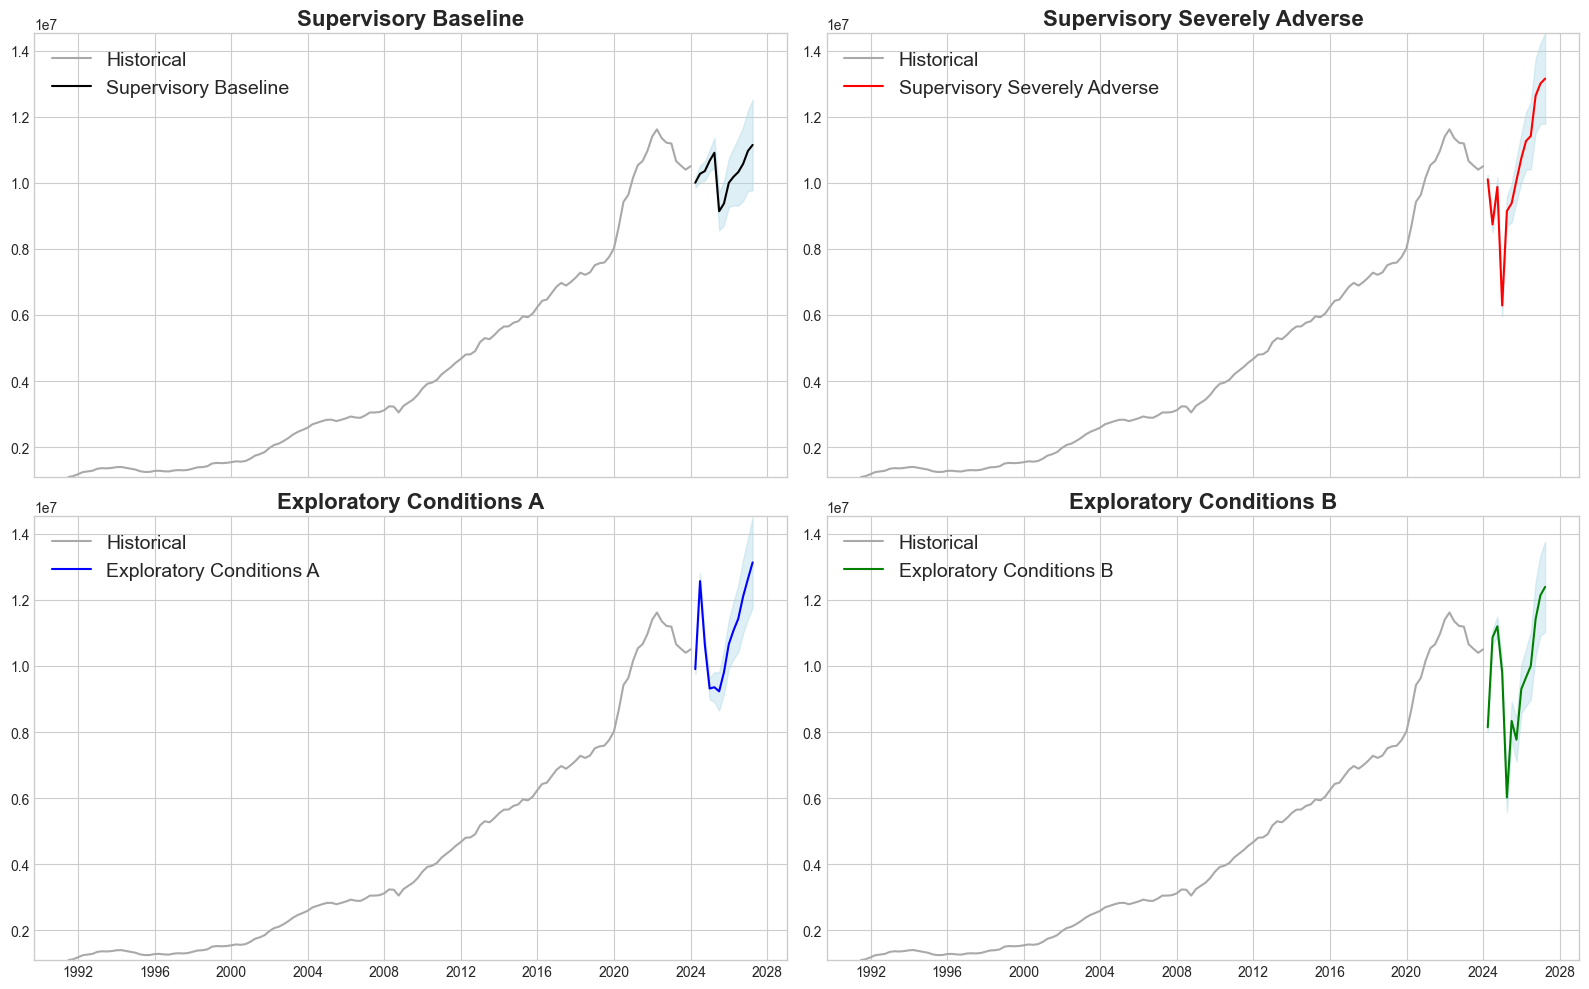

In [71]:
# Define colors dictionary
colors = {
    'Supervisory Baseline': 'black',
    'Supervisory Severely Adverse': 'red',
    'Exploratory Conditions A': 'blue',
    'Exploratory Conditions B': 'green'
}

scenario_list = list(forecasts.keys())
titles = {
    'Supervisory Baseline': 'Supervisory Baseline',
    'Supervisory Severely Adverse': 'Supervisory Severely Adverse',
    'Exploratory Conditions A': 'Exploratory Conditions A',
    'Exploratory Conditions B': 'Exploratory Conditions B'
}

# --- Determine global y-axis limits for all scenarios ---
y_min = min(
    y.min(), 
    min(forecasts[s]['ci'].iloc[:, 0].min() for s in scenario_list)
)
y_max = max(
    y.max(), 
    max(forecasts[s]['ci'].iloc[:, 1].max() for s in scenario_list)
)

# --- Create 2x2 grid ---
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True, sharey=True)
axes = axes.flatten()

for i, ax in enumerate(axes):
    if i < len(scenario_list):
        scenario_name = scenario_list[i]
        forecast_data = forecasts[scenario_name]
        color = colors.get(scenario_name, 'yellow')

        # Plot historical + forecast
        ax.plot(y.index, y, label='Historical', color='darkgray')
        ax.plot(forecast_data['mean'].index, forecast_data['mean'], 
                label=f'{scenario_name}', color=color)
        ax.fill_between(forecast_data['ci'].index, 
                        forecast_data['ci'].iloc[:, 0], 
                        forecast_data['ci'].iloc[:, 1], 
                        color='lightblue', alpha=0.4)
        
        # Titles and labels
        ax.set_title(titles.get(scenario_name, scenario_name), fontweight='bold', fontsize=16)
        ax.set_ylim(y_min, y_max)                # keep same scale
        ax.tick_params(left=True, labelleft=True) # ensure y-axis on left
        ax.legend(prop={'size': 14}, framealpha=0.9)
        ax.grid(True)

        # --- Save each subplot separately ---
        fig_single, ax_single = plt.subplots(figsize=(8, 5))
        ax_single.plot(y.index, y, label='Historical', color='darkgray')
        ax_single.plot(forecast_data['mean'].index, forecast_data['mean'], label=f'{scenario_name}', color=color)
        ax_single.fill_between(forecast_data['ci'].index, 
                               forecast_data['ci'].iloc[:, 0], 
                               forecast_data['ci'].iloc[:, 1], 
                               color='lightblue', alpha=0.4)
        ax_single.set_title(titles.get(scenario_name, scenario_name), fontweight='bold', fontsize=16)
        ax_single.set_ylim(y_min, y_max)          # same scale
        ax.tick_params(left=True, labelleft=True) # ensure y-axis on left
        ax_single.legend(prop={'size': 14}, framealpha=0.9)
        ax_single.grid(True)
        plt.tight_layout()
        plt.savefig(f'graphs/non-maturity-IB/non-maturity-IB_{scenario_name}_forecast.png', dpi=300, bbox_inches='tight')
        plt.close(fig_single)
    else:
        ax.axis('off')  # hide any empty subplots

# --- Save combined 2x2 grid ---
plt.tight_layout()
plt.savefig('graphs/non-maturity-IB/non-maturity-IB_forecasts.png', dpi=300, bbox_inches='tight')
plt.show()


**Supervisory Baseline (black line)**

- Treasury yields fall modestly (3% from 5.3%→3.1%), CPI inflation eases (2.4%→1.3%), unemployment remains low (3.9%→4.1%), and disposable income growth stays positive (2.5%→1.8%)

- Deposits rise steadily but gently—from about $11.0Tn to $12.5Tn—reflecting moderate rate cuts and steady income, which drives gradual deposit inflows without panic or hoarding

**Supervisory Severely Adverse (red line)**

- Short‐term rates collapse (3m from 5.3%→0.1%), unemployment spikes (3.9%→10%), stock market plunges (47,788→26,130), and volatility soars (VIX from 24.6→40.2)

- Deposits jump sharply—from $11.0Tn down to $6.2Tn briefly (reflecting withdrawals during initial stress), then surge to $13.2 million—consistent with rapid cash hoarding once markets and rates normalize

**Exploratory Conditions A (blue line)**
- Economy plunges (GDP growth from +0.9%→–11.6%), rates peak (3% to 6.8%), unemployment rises (4.0%→8.0%) then recovers by 2026

- Deposits first collapse—from $11.0Tn to $9.1Tn—as high rates damp spending, then recover sharply to $13.0Tn alongside rebounding income and falling rates

**Exploratory Conditions B (green line)**

- A prolonged downturn (GDP growth only modestly recovers from –2.4% to +5.1%), with rates easing slowly (3% to 3.1%) and unemployment remaining elevated (~6%)

- Deposits steadily climb—from $11.0Tn to $12.2Tn—reflecting gradual flight‐to‐safety and steady accumulation as deposit yields become relatively attractive compared to weak growth